# Aula 9 – Associação e comparação entre abordagens de modelagem

## Versão do aluno — com apresentação visual dos resultados

### Objetivo da aula
Aplicar algoritmos de associação para identificar padrões frequentes em uma base industrial e comparar essa abordagem com classificação, regressão e agrupamento.

### Instruções
Complete as células indicadas ao longo da atividade e registre suas interpretações técnicas.  
Nesta versão, você também deverá **gerar gráficos** para visualizar os resultados.


## 1. Instalação e importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura da base;
- visualização com matplotlib;
- Apriori;
- FP-growth;
- geração de regras de associação.


In [6]:
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
# Se necessário, descomente a linha abaixo
# !pip install mlxtend

In [8]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

## 2. Leitura da base

Leia o arquivo `dados_aula9_associacao_industrial.csv` e exiba as primeiras linhas.


In [9]:
# Complete aqui
df = pd.read_csv('dados_aula9_associacao_industrial.csv')
df.head()

,id_registro,linha,turno,produto,alta_temperatura,alta_pressao,alta_vibracao,tempo_resposta_lento,erro_vazao_alto,leituras_invalidas_altas,valvula_desregulada,bomba_desgastada,consumo_energia_alto,manutencao_urgente
0,ASSOC_0001,Linha_B,Tarde,Base,Não,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não
1,ASSOC_0002,Linha_A,Manhã,Base,Não,Não,Sim,Não,Não,Não,Não,Sim,Sim,Sim
2,ASSOC_0003,Linha_A,Noite,Solvente,Sim,Não,Sim,Não,Não,Não,Não,Não,Sim,Não
3,ASSOC_0004,Linha_B,Manhã,Acido,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não,Não
4,ASSOC_0005,Linha_B,Tarde,Acido,Sim,Sim,Não,Não,Sim,Não,Não,Não,Não,Não


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas;
- valores únicos das colunas contextuais.

**Registro técnico:**
- Há inconsistências de grafia?
- Há duplicatas?
- O que deve ser ajustado antes de gerar regras?


In [10]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:', df.duplicated().sum())

for col in ['linha', 'turno', 'produto']:
  print(f'\nValores únicos em {col}:', sorted(df[col].dropna().astype(str).unique()))

Dimensão da base: (270, 14)

Tipos de dados:
id_registro                 object
linha                       object
turno                       object
produto                     object
alta_temperatura            object
alta_pressao                object
alta_vibracao               object
tempo_resposta_lento        object
erro_vazao_alto             object
leituras_invalidas_altas    object
valvula_desregulada         object
bomba_desgastada            object
consumo_energia_alto        object
manutencao_urgente          object
dtype: object

Valores faltantes:
id_registro                  0
linha                       10
turno                        0
produto                      0
alta_temperatura             0
alta_pressao                 0
alta_vibracao                0
tempo_resposta_lento         0
erro_vazao_alto              0
leituras_invalidas_altas     0
valvula_desregulada          0
bomba_desgastada             0
consumo_energia_alto         0
manutencao_urgente          

**Registro do aluno:**  
-  Sim, há colunas repetidas que foram consideradas colunas diferentes por conta da grafia.
-  Sim, há 10 duplicatas.
-  Toda tratativa das duplicatas, valores nulos, colunas duplicadas, deve ser feita.

## 4. Limpeza básica

Realize os ajustes necessários:
- remova duplicatas;
- preencha faltantes com a moda;
- padronize categorias com grafia inconsistente.


In [11]:
# Complete aqui
df = df.drop_duplicates().copy()

for col in ['linha', 'turno', 'produto']:
  df[col] = df[col].fillna(df[col].mode()[0]).astype(str).str.strip()

df['produto'] = df['produto'].replace({'acido': 'Acido'})
df['turno'] = df['turno'].replace({'noite': 'Noite'})

df.head()

,id_registro,linha,turno,produto,alta_temperatura,alta_pressao,alta_vibracao,tempo_resposta_lento,erro_vazao_alto,leituras_invalidas_altas,valvula_desregulada,bomba_desgastada,consumo_energia_alto,manutencao_urgente
0,ASSOC_0001,Linha_B,Tarde,Base,Não,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não
1,ASSOC_0002,Linha_A,Manhã,Base,Não,Não,Sim,Não,Não,Não,Não,Sim,Sim,Sim
2,ASSOC_0003,Linha_A,Noite,Solvente,Sim,Não,Sim,Não,Não,Não,Não,Não,Sim,Não
3,ASSOC_0004,Linha_B,Manhã,Acido,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não,Não
4,ASSOC_0005,Linha_B,Tarde,Acido,Sim,Sim,Não,Não,Sim,Não,Não,Não,Não,Não


## 5. Preparação da base para associação

Transforme as colunas binárias de **Sim/Não** para **1/0** e gere colunas dummies para `linha`, `turno` e `produto`.


In [12]:
# Complete aqui
colunas_binarias = [
    'alta_temperatura', 'alta_pressao', 'alta_vibracao', 'tempo_resposta_lento',
    'erro_vazao_alto', 'leituras_invalidas_altas', 'valvula_desregulada',
    'bomba_desgastada', 'consumo_energia_alto', 'manutencao_urgente'
]

df_bin = df.copy()

for col in colunas_binarias:
    df_bin[col] = df_bin[col].map({'Sim': 1, 'Não': 0})

df_contexto = pd.get_dummies(
    df_bin[['linha', 'turno', 'produto']],
    prefix=['linha', 'turno', 'produto']
)

df_regras = pd.concat([df_bin[colunas_binarias], df_contexto], axis=1)
df_regras.head()

,alta_temperatura,alta_pressao,alta_vibracao,tempo_resposta_lento,erro_vazao_alto,leituras_invalidas_altas,valvula_desregulada,bomba_desgastada,consumo_energia_alto,manutencao_urgente,linha_Linha_A,linha_Linha_B,linha_Linha_C,turno_Manhã,turno_Noite,turno_Tarde,produto_Acido,produto_Base,produto_Solvente
0,0,1,1,1,0,0,0,0,1,0,False,True,False,False,False,True,False,True,False
1,0,0,1,0,0,0,0,1,1,1,True,False,False,True,False,False,False,True,False
2,1,0,1,0,0,0,0,0,1,0,True,False,False,False,True,False,False,False,True
3,1,1,1,0,0,0,0,1,0,0,False,True,False,True,False,False,True,False,False
4,1,1,0,0,1,0,0,0,0,0,False,True,False,False,False,True,True,False,False


## 6. Visualização inicial dos itens mais frequentes

Calcule a frequência relativa dos itens e faça um gráfico com os 10 itens mais frequentes.


In [13]:
# Complete aqui
frequencia_itens = df_regras.mean().sort_values(ascending=False)
frequencia_itens.head(10)

,0
consumo_energia_alto,0.469231
alta_pressao,0.450000
alta_temperatura,0.430769
linha_Linha_B,0.411538
alta_vibracao,0.376923
linha_Linha_A,0.369231
turno_Manhã,0.365385
produto_Base,0.353846
produto_Acido,0.342308
turno_Tarde,0.338462


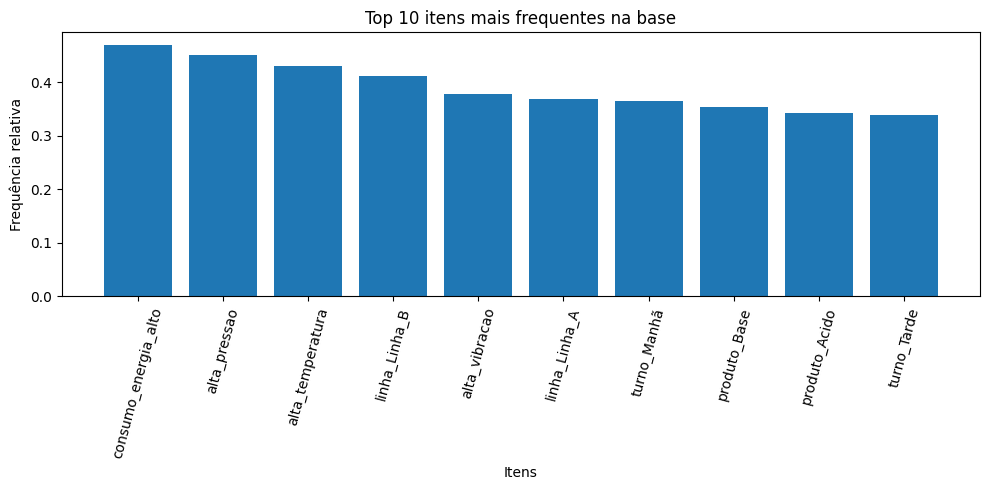

In [14]:
# Gere o gráfico aqui
top_itens = frequencia_itens.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_itens.index, top_itens.values)
plt.title('Top 10 itens mais frequentes na base')
plt.xlabel('Itens')
plt.ylabel('Frequência relativa')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 7. Conceitos fundamentais

Explique, com suas palavras:
- o que é **suporte**;
- o que é **confiança**;
- o que significa **lift** maior que 1.


**Resposta do aluno:**  
- Suporte:  
- Confiança:  
- Lift > 1:  


## 8. Geração de itemsets frequentes com Apriori

Aplique o algoritmo Apriori com suporte mínimo de 0,08.


In [16]:
# Complete aqui
itemsets_apriori = apriori(df_regras, min_support = 0.08, use_colnames = True)
itemsets_apriori = itemsets_apriori.sort_values(by = 'support', ascending = False)
itemsets_apriori.head(15)

,support,itemsets
8,0.469231,(consumo_energia_alto)
1,0.45,(alta_pressao)
0,0.430769,(alta_temperatura)
11,0.411538,(linha_Linha_B)
2,0.376923,(alta_vibracao)
10,0.369231,(linha_Linha_A)
13,0.365385,(turno_Manhã)
17,0.353846,(produto_Base)
16,0.342308,(produto_Acido)
15,0.338462,(turno_Tarde)


## 9. Visualização dos itemsets mais frequentes

Crie uma coluna em formato de texto para os itemsets e faça um gráfico com os 10 itemsets de maior suporte.


In [17]:
# Complete aqui
top_itemsets_apriori = itemsets_apriori.head(10).copy()
top_itemsets_apriori['itemset_str'] = top_itemsets_apriori['itemsets'].apply(lambda x: ', '.join(sorted(list(x))))
top_itemsets_apriori[['itemset_str', 'support']]

,itemset_str,support
8,consumo_energia_alto,0.469231
1,alta_pressao,0.45
0,alta_temperatura,0.430769
11,linha_Linha_B,0.411538
2,alta_vibracao,0.376923
10,linha_Linha_A,0.369231
13,turno_Manhã,0.365385
17,produto_Base,0.353846
16,produto_Acido,0.342308
15,turno_Tarde,0.338462


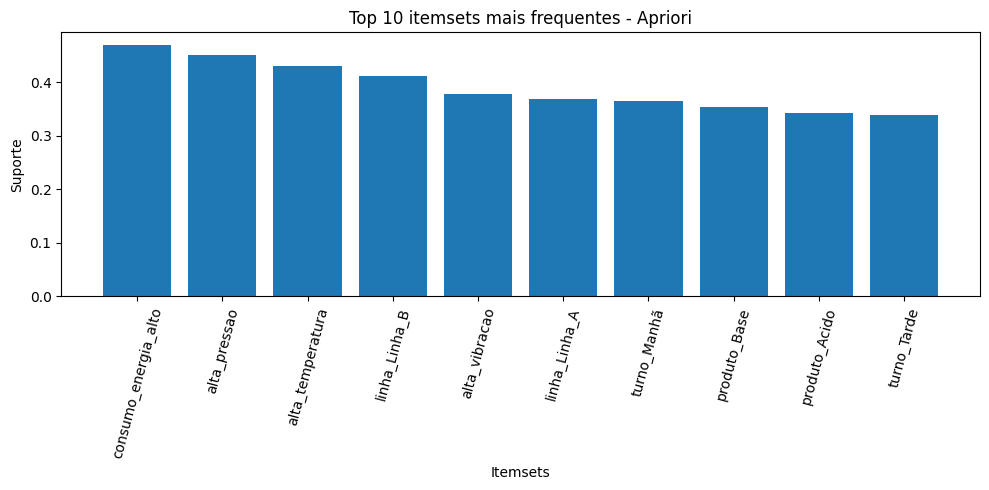

In [18]:
# Gere o gráfico aqui
plt.figure(figsize=(10, 5))
plt.bar(top_itemsets_apriori['itemset_str'], top_itemsets_apriori['support'])
plt.title('Top 10 itemsets mais frequentes - Apriori')
plt.xlabel('Itemsets')
plt.ylabel('Suporte')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 10. Geração das regras de associação com Apriori

Gere regras usando confiança mínima de 0,6 e exiba as principais.


In [19]:
# Complete aqui
regras_apriori = association_rules(itemsets_apriori, metric = 'confidence', min_threshold = 0.6)
regras_apriori = regras_apriori.sort_values(by=['lift', 'confidence'], ascending=False)

regras_apriori[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15)

,antecedents,consequents,support,confidence,lift
64,"(alta_temperatura, valvula_desregulada)",(erro_vazao_alto),0.088462,0.696970,3.020202
39,"(valvula_desregulada, alta_pressao)",(erro_vazao_alto),0.092308,0.648649,2.810811
56,"(leituras_invalidas_altas, alta_vibracao)",(tempo_resposta_lento),0.088462,0.741935,2.606800
41,"(alta_pressao, erro_vazao_alto)",(valvula_desregulada),0.092308,0.705882,2.584921
30,"(bomba_desgastada, tempo_resposta_lento)",(alta_vibracao),0.100000,0.962963,2.554800
63,"(bomba_desgastada, produto_Base)",(alta_vibracao),0.088462,0.958333,2.542517
46,"(leituras_invalidas_altas, alta_pressao)",(tempo_resposta_lento),0.092308,0.705882,2.480127
47,"(alta_pressao, tempo_resposta_lento)",(leituras_invalidas_altas),0.092308,0.615385,2.461538
20,"(alta_pressao, alta_vibracao)",(bomba_desgastada),0.115385,0.652174,2.457467
13,"(consumo_energia_alto, alta_vibracao)",(bomba_desgastada),0.142308,0.649123,2.445970


## 11. Visualização das principais regras do Apriori

Monte uma coluna de texto com as regras e faça:
- um gráfico das principais regras por **lift**;
- um gráfico das principais regras por **confiança**.


In [21]:
# Complete aqui
top_regras_apriori = regras_apriori[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).copy()
top_regras_apriori['regra'] = top_regras_apriori.apply(
    lambda row: f"{';'.join(sorted(list(row['antecedents'])))} -> {';'.join(sorted(list(row['consequents'])))}",
    axis=1
)

top_regras_apriori[['regra', 'support', 'confidence', 'lift']]

,regra,support,confidence,lift
64,alta_temperatura;valvula_desregulada -> erro_v...,0.088462,0.696970,3.020202
39,alta_pressao;valvula_desregulada -> erro_vazao...,0.092308,0.648649,2.810811
56,alta_vibracao;leituras_invalidas_altas -> temp...,0.088462,0.741935,2.606800
41,alta_pressao;erro_vazao_alto -> valvula_desreg...,0.092308,0.705882,2.584921
30,bomba_desgastada;tempo_resposta_lento -> alta_...,0.100000,0.962963,2.554800
63,bomba_desgastada;produto_Base -> alta_vibracao,0.088462,0.958333,2.542517
46,alta_pressao;leituras_invalidas_altas -> tempo...,0.092308,0.705882,2.480127
47,alta_pressao;tempo_resposta_lento -> leituras_...,0.092308,0.615385,2.461538
20,alta_pressao;alta_vibracao -> bomba_desgastada,0.115385,0.652174,2.457467
13,alta_vibracao;consumo_energia_alto -> bomba_de...,0.142308,0.649123,2.445970


/tmp/ipykernel_180/2714360110.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


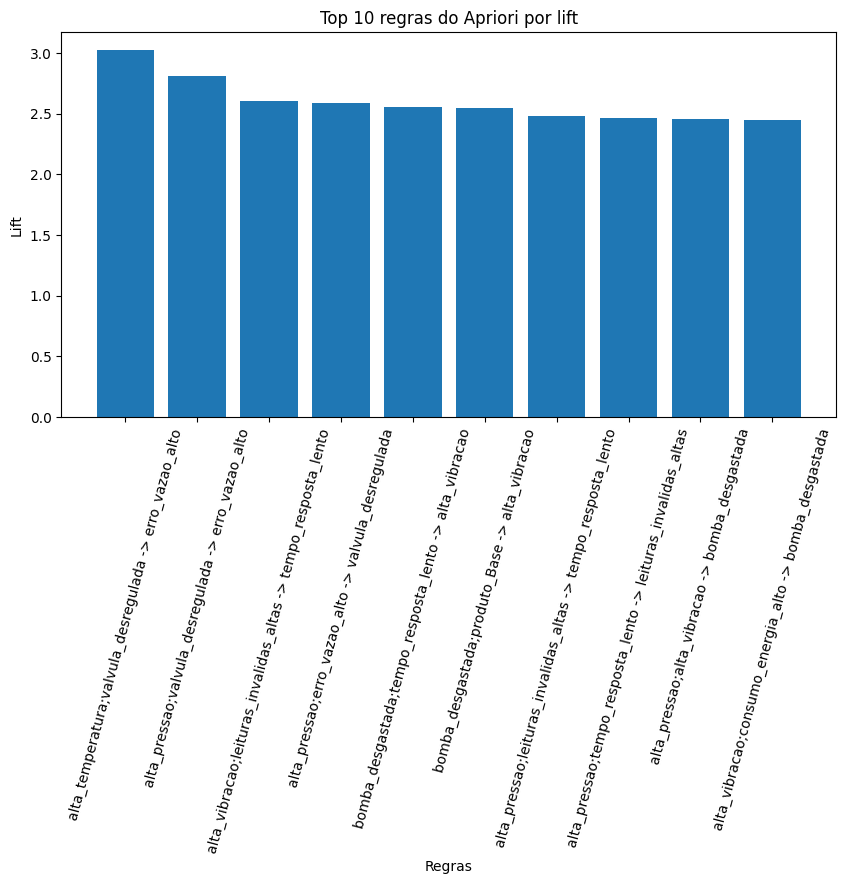

In [22]:
# Gere o gráfico de lift aqui
plt.figure(figsize=(10, 5))
plt.bar(top_regras_apriori['regra'], top_regras_apriori['lift'])
plt.title('Top 10 regras do Apriori por lift')
plt.xlabel('Regras')
plt.ylabel('Lift')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

/tmp/ipykernel_180/967186997.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


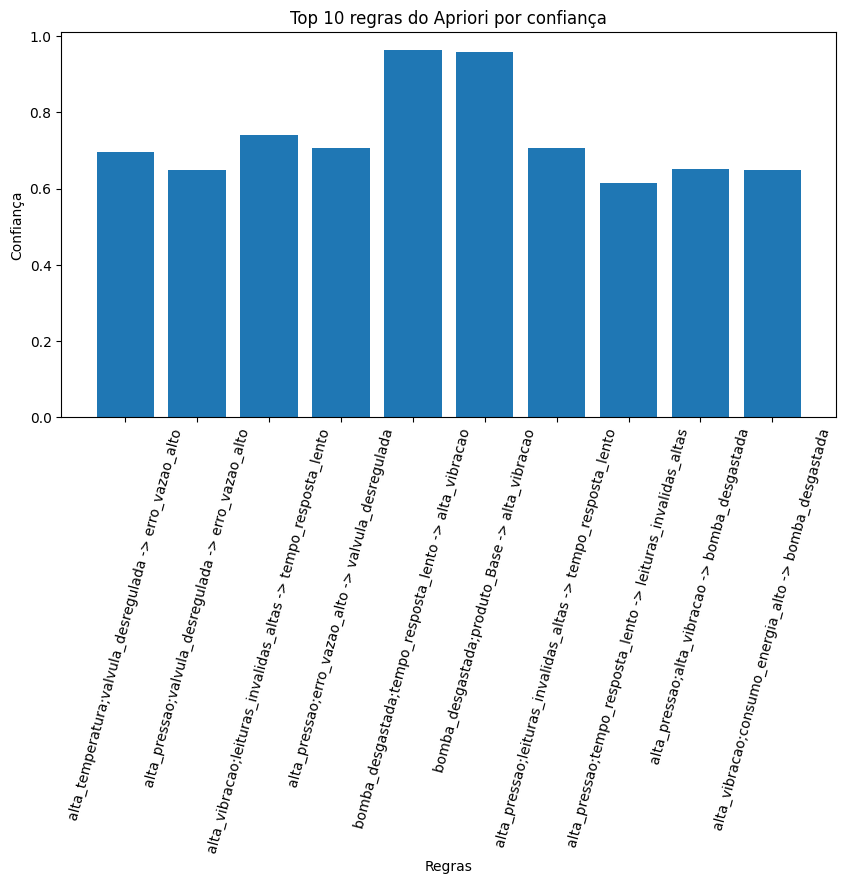

In [23]:
# Gere o gráfico de confiança aqui
plt.figure(figsize=(10, 5))
plt.bar(top_regras_apriori['regra'], top_regras_apriori['confidence'])
plt.title('Top 10 regras do Apriori por confiança')
plt.xlabel('Regras')
plt.ylabel('Confiança')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 12. Geração de itemsets e regras com FP-growth

Repita o processo com FP-growth.


In [24]:
# Complete aqui
itemsets_fpgrowth = fpgrowth(df_regras, min_support = 0.08, use_colnames = True)
itemsets_fpgrowth = itemsets_fpgrowth.sort_values(by='support', ascending=False)

regras_fpgrowth = association_rules(itemsets_fpgrowth, metric = 'confidence', min_threshold = 0.6)
regras_fpgrowth = regras_fpgrowth.sort_values(by=['lift', 'confidence'], ascending=False)

regras_fpgrowth[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15)

,antecedents,consequents,support,confidence,lift
59,"(alta_temperatura, valvula_desregulada)",(erro_vazao_alto),0.088462,0.696970,3.020202
51,"(valvula_desregulada, alta_pressao)",(erro_vazao_alto),0.092308,0.648649,2.810811
61,"(leituras_invalidas_altas, alta_vibracao)",(tempo_resposta_lento),0.088462,0.741935,2.606800
53,"(alta_pressao, erro_vazao_alto)",(valvula_desregulada),0.092308,0.705882,2.584921
30,"(bomba_desgastada, tempo_resposta_lento)",(alta_vibracao),0.100000,0.962963,2.554800
56,"(bomba_desgastada, produto_Base)",(alta_vibracao),0.088462,0.958333,2.542517
46,"(leituras_invalidas_altas, alta_pressao)",(tempo_resposta_lento),0.092308,0.705882,2.480127
47,"(alta_pressao, tempo_resposta_lento)",(leituras_invalidas_altas),0.092308,0.615385,2.461538
21,"(alta_pressao, alta_vibracao)",(bomba_desgastada),0.115385,0.652174,2.457467
14,"(consumo_energia_alto, alta_vibracao)",(bomba_desgastada),0.142308,0.649123,2.445970


## 13. Visualização das principais regras do FP-growth

Crie uma visualização das principais regras por lift.


In [25]:
# Complete aqui
top_regras_fpgrowth = regras_fpgrowth[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).copy()
top_regras_fpgrowth['regra'] = top_regras_fpgrowth.apply(
    lambda row: f"{', '.join(sorted(list(row['antecedents'])))} -> {','.join(sorted(list(row['consequents'])))}",
    axis=1
)

top_regras_fpgrowth[['regra', 'support', 'confidence', 'lift']]

,regra,support,confidence,lift
59,"alta_temperatura, valvula_desregulada -> erro_...",0.088462,0.696970,3.020202
51,"alta_pressao, valvula_desregulada -> erro_vaza...",0.092308,0.648649,2.810811
61,"alta_vibracao, leituras_invalidas_altas -> tem...",0.088462,0.741935,2.606800
53,"alta_pressao, erro_vazao_alto -> valvula_desre...",0.092308,0.705882,2.584921
30,"bomba_desgastada, tempo_resposta_lento -> alta...",0.100000,0.962963,2.554800
56,"bomba_desgastada, produto_Base -> alta_vibracao",0.088462,0.958333,2.542517
46,"alta_pressao, leituras_invalidas_altas -> temp...",0.092308,0.705882,2.480127
47,"alta_pressao, tempo_resposta_lento -> leituras...",0.092308,0.615385,2.461538
21,"alta_pressao, alta_vibracao -> bomba_desgastada",0.115385,0.652174,2.457467
14,"alta_vibracao, consumo_energia_alto -> bomba_d...",0.142308,0.649123,2.445970


/tmp/ipykernel_180/2557511750.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


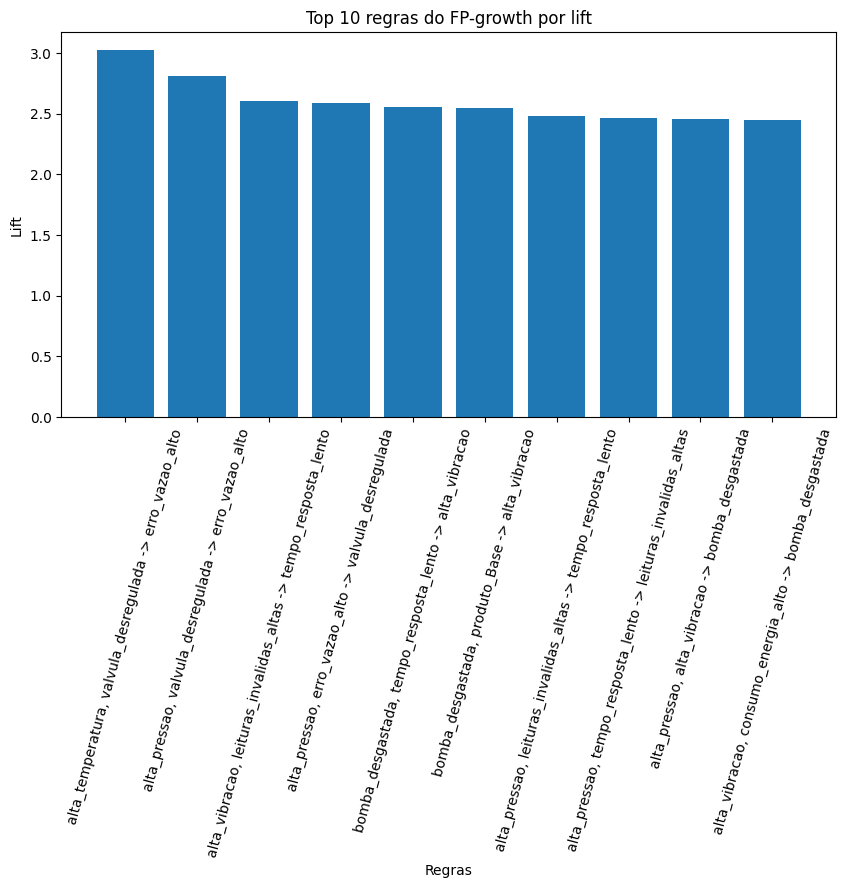

In [26]:
# Gere o gráfico aqui
plt.figure(figsize=(10, 5))
plt.bar(top_regras_fpgrowth['regra'], top_regras_fpgrowth['lift'])
plt.title('Top 10 regras do FP-growth por lift')
plt.xlabel('Regras')
plt.ylabel('Lift')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 14. Comparação visual entre Apriori e FP-growth

Monte uma tabela comparando:
- quantidade de itemsets;
- quantidade de regras.

Depois, faça dois gráficos de barras.


In [27]:
# Complete aqui
comparacao_algoritmos = pd.DataFrame({
  'Algoritmo': ['Apriori', 'FP-growth'],
  'Quantidade_itemsets': [len(itemsets_apriori), len(itemsets_fpgrowth)],
  'Quantidade_regras': [len(regras_apriori), len(regras_fpgrowth)]
})

comparacao_algoritmos

,Algoritmo,Quantidade_itemsets,Quantidade_regras
0,Apriori,193,82
1,FP-growth,193,82


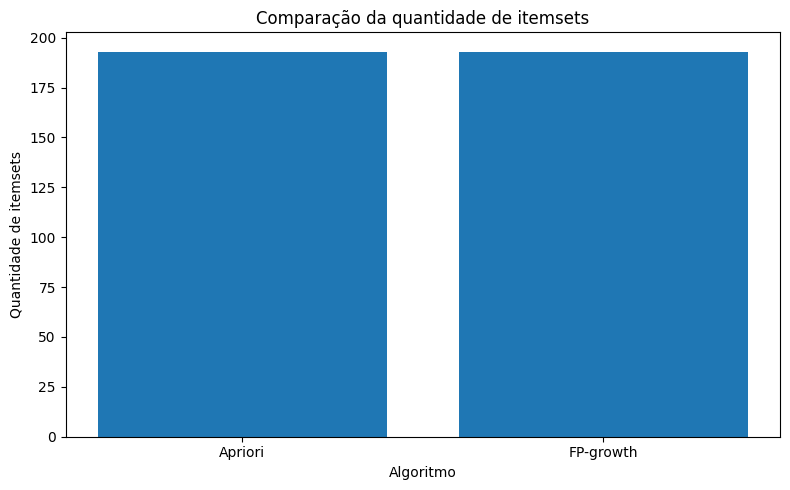

In [28]:
# Gere o gráfico de itemsets aqui
plt.figure(figsize=(8, 5))
plt.bar(comparacao_algoritmos['Algoritmo'], comparacao_algoritmos['Quantidade_itemsets'])
plt.title('Comparação da quantidade de itemsets')
plt.xlabel('Algoritmo')
plt.ylabel('Quantidade de itemsets')
plt.tight_layout()
plt.show()

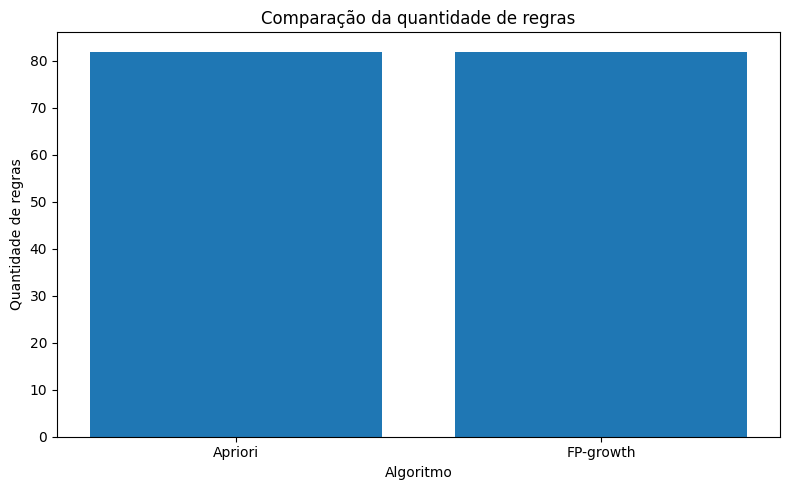

In [29]:
# Gere o gráfico de regras aqui
plt.figure(figsize=(8, 5))
plt.bar(comparacao_algoritmos['Algoritmo'], comparacao_algoritmos['Quantidade_regras'])
plt.title('Comparação da quantidade de regras')
plt.xlabel('Algoritmo')
plt.ylabel('Quantidade de regras')
plt.tight_layout()
plt.show()

## 15. Interpretação das regras encontradas

Observe as principais regras e responda:
- quais eventos aparecem juntos com frequência;
- quais regras parecem úteis para manutenção ou monitoramento;
- que relações chamaram mais atenção.


In [30]:
# Exiba aqui as principais regras
top_regras_apriori[['regra', 'support', 'confidence', 'lift']]

,regra,support,confidence,lift
64,alta_temperatura;valvula_desregulada -> erro_v...,0.088462,0.696970,3.020202
39,alta_pressao;valvula_desregulada -> erro_vazao...,0.092308,0.648649,2.810811
56,alta_vibracao;leituras_invalidas_altas -> temp...,0.088462,0.741935,2.606800
41,alta_pressao;erro_vazao_alto -> valvula_desreg...,0.092308,0.705882,2.584921
30,bomba_desgastada;tempo_resposta_lento -> alta_...,0.100000,0.962963,2.554800
63,bomba_desgastada;produto_Base -> alta_vibracao,0.088462,0.958333,2.542517
46,alta_pressao;leituras_invalidas_altas -> tempo...,0.092308,0.705882,2.480127
47,alta_pressao;tempo_resposta_lento -> leituras_...,0.092308,0.615385,2.461538
20,alta_pressao;alta_vibracao -> bomba_desgastada,0.115385,0.652174,2.457467
13,alta_vibracao;consumo_energia_alto -> bomba_de...,0.142308,0.649123,2.445970


**Interpretação do aluno:**  
-  Os eventos que aparecem com mais frequência são: `alta_vibracao` + `consumo_energia_alto` -> `bomba_desgastada`, com 0.14 dos casos, e `alta_pressao` + `alta_vibracao` -> `bomba_desgastada`, com 0.115 dos casos.
-  As regras úteis para monitoramento são: `bomba_desgastada; tempo_resposta_lento -> alta_...` e `bomba_desgastada; produto_Base -> alta_vibracao`
-  `alta_temperatura; valvula_desregulada -> erro_vazao...` Chamou mais atenção por ter um grande lift na tabela, indicando uma forte correlação entre falha de controle térmico/mecânico e erro de vazão.

## 16. Comparação entre abordagens de modelagem

Preencha um quadro comparativo entre:
- associação;
- classificação;
- regressão;
- agrupamento.


In [31]:
# Complete aqui
quadro_comparativo = pd.DataFrame({
  'Abordagem': ['Associação', 'Classificação', 'Regressão', 'Agrupamento'],
  'Pergunta_típica': [
    'Quais eventos tendem a ocorrer juntos?',
    'Em qual classe este registro se encaixa?',
    'Qual valor contínuo queremos estimar?',
    'Quais grupos semelhantes existem na base?'
  ],
  'Tipo_de_aprendizado': [
    'Não supervisionado',
    'Supervisionado',
    'Supervisionado',
    'Não supervisionado'
  ],
  'Exemplo_industrial': [
    'Combinação frequente de falhas e condições operacionais',
    'Prever status de falha',
    'Prever vazão, temperatura ou consumo',
    'Identificar perfis operacionais'
  ]
})
quadro_comparativo

,Abordagem,Pergunta_típica,Tipo_de_aprendizado,Exemplo_industrial
0,Associação,Quais eventos tendem a ocorrer juntos?,Não supervisionado,Combinação frequente de falhas e condições ope...
1,Classificação,Em qual classe este registro se encaixa?,Supervisionado,Prever status de falha
2,Regressão,Qual valor contínuo queremos estimar?,Supervisionado,"Prever vazão, temperatura ou consumo"
3,Agrupamento,Quais grupos semelhantes existem na base?,Não supervisionado,Identificar perfis operacionais


## 17. Visualização sintética das abordagens

Gere um gráfico simples para representar as abordagens estudadas na aula.


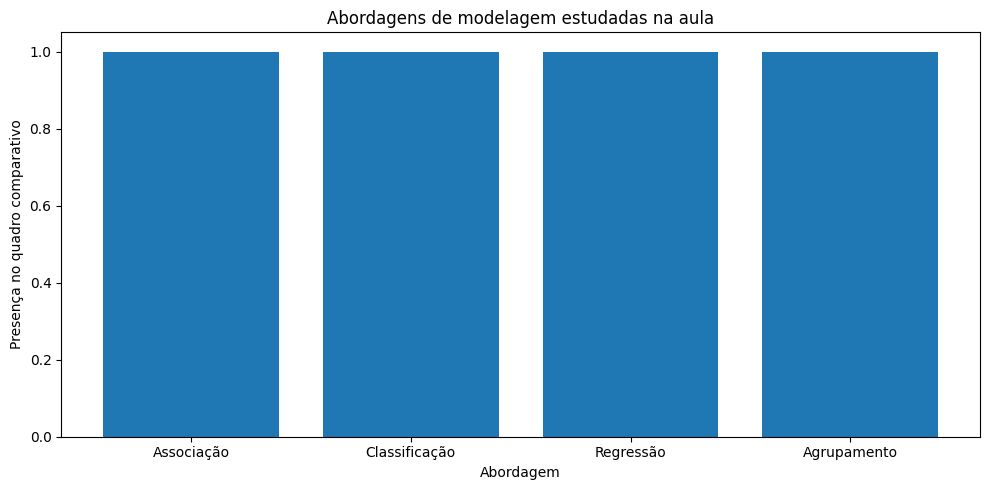

In [32]:
# Gere o gráfico aqui
plt.figure(figsize=(10, 5))
plt.bar(quadro_comparativo['Abordagem'], [1, 1, 1, 1])
plt.title('Abordagens de modelagem estudadas na aula')
plt.xlabel('Abordagem')
plt.ylabel('Presença no quadro comparativo')
plt.tight_layout()
plt.show()

## 18. Definição do problema e escolha da abordagem

Escreva:
- qual problema pode ser tratado por associação;
- quando seria melhor usar classificação;
- quando seria melhor usar regressão;
- quando o agrupamento faria mais sentido.


**Resposta do aluno:**  
- Associação: Problemas que buscam descobrir regras de coocorrência, padrões frequentes ou relações lógicas entre itens em grandes bases de dados
- Classificação: Quando o objetivo é prever uma categoria, rótulo ou classe discreta para uma nova observação com base em dados históricos rotulados.
- Regressão: Quando o objetivo é prever um valor numérico contínuo com base em variáveis preditoras.
- Agrupamento: Quando se trabalha com dados não rotulados e o objetivo é explorar os dados para descobrir grupos naturais, segmentações ou perfis semelhantes com base em suas características intrínsecas, sem ter respostas prévias definidas.


## 19. Exportação dos resultados

Salve:
1. um arquivo CSV com as regras encontradas;
2. um arquivo CSV com o quadro comparativo;
3. um arquivo CSV com a comparação entre Apriori e FP-growth.


In [33]:
# Complete aqui
regras_apriori[['antecedents', 'consequents', 'support', 'confidence', 'lift']].to_csv('regras_associacao_apriori_aula9_visual.csv', index = False)
quadro_comparativo.to_csv('quadro_comparativo_modelagem_aula9_visual.csv', index = False)
comparacao_algoritmos.to_csv('comparacao_apriori_fpgrowth_aula9.csv', index = False)
print('Arquivos exportados com sucesso.')

Arquivos exportados com sucesso.


## 20. Fechamento

Verifique se você:
- diferenciou corretamente as finalidades dos algoritmos estudados;
- comparou as abordagens com coerência técnica;
- selecionou modelos pertinentes ao caso industrial;
- registrou sua justificativa de forma organizada;
- apresentou os resultados de forma visual para facilitar a interpretação.
